# Data Workflow

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/05-RotationProfiles/053-WorkflowData.ipynb)
:::

In the [previous section](052-Workflow.ipynb) we ran nineteen constrained optimizations of butane and saved the results in the file `butane_scan_HF321G.json`. If you open it in a text editor you will see nineteen **records** of data, one for each torsion angle, each looking like this.

```text
  {
    "Torsion":0,
    "Final torsion":0.0,
    "Energy":-156.42...,
    "Steps":...,
    "Max gradient":...
  },
```

The torsion angle that we froze comes first, then the torsion measured after the optimization. The energy follows and the value is in units of Hartrees/molecule. We will want to convert that to *kJ/mol*. Then we have the number of optimization steps, and the largest component of the energy gradient for the last structure of the optimization.

In the *GAMESS* book, the equivalent file was a jumble of text lines pulled out of the log files with *grep*, and half of this notebook was spent cutting it into columns. JSON files keep the column **names** with the data, so our job is easier.

This notebook does not run *Psi4*, so the hidden first cell only imports *NumPy*, *pandas*, *Matplotlib* and *SciPy* and applies the plot style sheet.

In [52]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Import Raw Data

We will do everything using the data analysis tools of *Python* and *pandas*. First we will import the data as a dataframe. If you ran the previous notebook, the data file is in the same folder as this notebook. If not (on *Google Colab*, for example), we will download my copy from the book's *GitHub* repository.

In [53]:
url = "https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/book/05-RotationProfiles/"

def load_scan(filename):
    if Path(filename).exists():
        return pd.read_json(filename)
    else:
        return pd.read_json(url + filename)

df = load_scan("butane_scan_HF321G.json")
df.head()

,Torsion,Final torsion,Energy,Steps,Max gradient
0,0,0.00043,-156.422846,10,0.000021
1,10,10.00000,-156.423373,10,0.000015
2,20,20.00000,-156.424789,9,0.000027
3,30,30.00000,-156.426702,9,0.000022
4,40,40.00000,-156.428643,8,0.000056


| Line | Notes |
| :---- | :---- |
| `url = ...` | The web address of this chapter's folder in the book's *GitHub* repository. |
| `Path(filename).exists()` | `True` if the file is in the same folder as this notebook. |
| `pd.read_json(...)` | Reads a JSON file, from the disk or from the web, and makes a **dataframe**. |
| `df.head()` | Shows the first five rows. |

Python will scream at you if you make a mistake and you will be able to fix any problems.

## Cleaning the Data

Data cleaning is half the work in data analysis. We need to drop empty records and malformed records (each line could be considered a record in this case). In our scan, a job that ran out of optimization steps was recorded with an energy of *NaN* ("not a number"). We will drop any such records. We also only need three of the columns: the torsion, the energy and the number of steps.

In [54]:
butane = df.dropna(subset=["Energy"])
butane = butane[["Torsion", "Energy", "Steps"]]

print(len(df) - len(butane), "records dropped")
butane.head()

0 records dropped


,Torsion,Energy,Steps
0,0,-156.422846,10
1,10,-156.423373,10
2,20,-156.424789,9
3,30,-156.426702,9
4,40,-156.428643,8


| Line | Notes |
| :---- | :---- |
| `df.dropna(subset=["Energy"])` | A new dataframe **without** the rows that have *NaN* in the `Energy` column. |
| `butane[["Torsion", "Energy", "Steps"]]` | Keep only these three **columns**. Note the double square brackets: the inner pair is a *Python* list of column names. |

No records were dropped. Every job converged.

## Processing the Data

We now have a cleaned up data set. We could have done all of this in a spreadsheet, but *Python* and *pandas* are not any more work, and the next time we only have to press "run".

We know that a Hartree is 2625.50 *kJ/mol*. So we can convert the energy to a more familiar unit. Then we should set our lowest energy structure as the zero reference and subtract that value from all the energies to establish a relative scale.

In [55]:
hartree_conversion = 2625.4996

lowest_energy = butane["Energy"].min()
butane["DeltaE"] = (butane["Energy"] - lowest_energy) * hartree_conversion
butane.round(4)

,Torsion,Energy,Steps,DeltaE
0,0,-156.4228,10,25.2570
1,10,-156.4234,10,23.8754
2,20,-156.4248,9,20.1571
3,30,-156.4267,9,15.1339
4,40,-156.4286,8,10.0391
5,50,-156.4302,8,5.9905
6,60,-156.4311,7,3.6883
7,70,-156.4312,6,3.2807
8,80,-156.4307,5,4.6669
9,90,-156.4296,5,7.5943


| Line | Notes |
| :---- | :---- |
| `hartree_conversion = 2625.4996` | *kJ/mol* per Hartree. This is the value stored in `psi4.constants.hartree2kJmol`, but we did not import *Psi4* in this notebook. |
| `butane["Energy"].min()` | The **lowest** energy in the column. |
| `butane["DeltaE"] = ...` | A new column of **relative** energies in *kJ/mol*. |

The lowest energy is at 180&deg;. The *syn* conformer at 0&deg; is 25.26 *kJ/mol* above it.

## Plotting the Profile

Now we have a set of data that we can plot. Let us visualize the profile using the *Matplotlib* library.

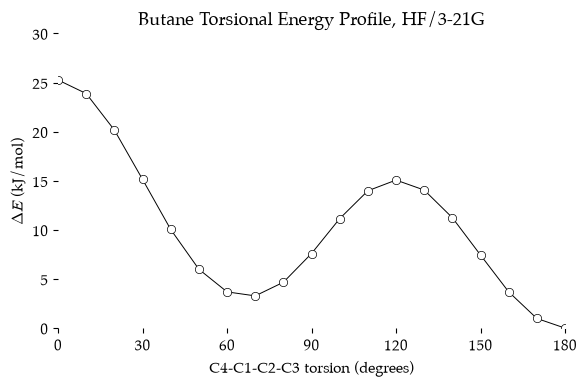

In [56]:
x = butane["Torsion"]
y = butane["DeltaE"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(x, y, color="black", linewidth=0.7, marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
ax.set_xlabel("C4-C1-C2-C3 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butane Torsional Energy Profile, HF/3-21G")
ax.set_xlim(0, 180)
ax.set_ylim(0, 30)
ax.set_xticks(np.arange(0, 181, 30))
plt.show()

The profile behaves as expected. A **maximum** at the *syn* conformation (0&deg;), a **minimum** for the *gauche* conformation, a second maximum near the *eclipsed* conformation and the global minimum at *anti* (180&deg;).

## Publication Quality

The plot above uses the style sheet that I edited to my preference (`tufte.mplstyle`, applied in the hidden first cell). Different journals have different standards for plots. Just follow their instructions. Many will have style sheets available for your word processor or for $\LaTeX$. Use the `savefig()` method of the `fig` object to save the plot as a file. The `.pdf` extension will tell it to save in PDF format.

```python
fig.savefig("butane_profile.pdf")
```

## A Smooth Curve

The plot above is a "connect-the-dots" style plot. There are many data points and it looks fine. We do not have an exact function to which to fit the data but we could apply the infamous "cubic spline." We will use the `CubicSpline` function available from the `scipy.interpolate` library ([Documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html)) to generate a function that represents the curve fit. We will then feed an *x*-axis of many data points into that function to create an *x*,*y* data set that represents that curve fit as a smooth line.

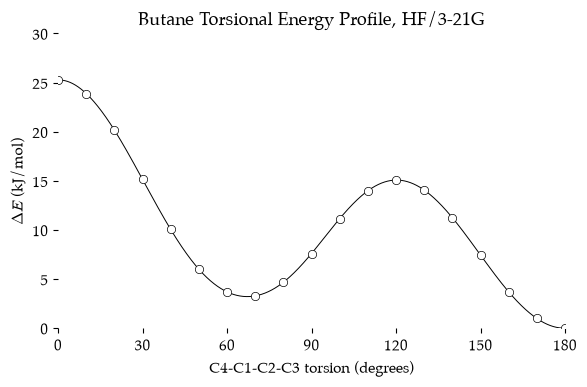

In [57]:
cs = CubicSpline(butane["Torsion"], butane["DeltaE"])
x_fit = np.arange(0, 180.1, 0.1)
y_fit = cs(x_fit)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(x_fit, y_fit, color="black", linewidth=0.7, zorder=1)
ax.plot(butane["Torsion"], butane["DeltaE"], linestyle="none", marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.set_xlabel("C4-C1-C2-C3 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butane Torsional Energy Profile, HF/3-21G")
ax.set_xlim(0, 180)
ax.set_ylim(0, 30)
ax.set_xticks(np.arange(0, 181, 30))
plt.show()

| Line | Notes |
| :---- | :---- |
| `CubicSpline(x, y)` | Makes a **function** `cs` that passes smoothly through every data point. |
| `np.arange(0, 180.1, 0.1)` | 1801 angles from 0&deg; to 180&deg;, every 0.1&deg;. |
| `cs(x_fit)` | The **value** of the spline at each of those angles. |
| `zorder=1`, `zorder=2` | The curve is drawn **underneath** the data points. |

### Where Are the Maximum and Minimum?

Now we can answer the question that we asked at the start of the workflow. Is the second maximum **at** 120&deg;, or is it offset? And where exactly is the *gauche* minimum? The spline gives us a value every 0.1&deg;, so we can simply look for the highest and lowest points in each region.

In [58]:
region = (x_fit > 90) & (x_fit < 150)
i_max = np.argmax(y_fit[region])
print(f"eclipsed maximum: {x_fit[region][i_max]:.1f} degrees, {y_fit[region][i_max]:.2f} kJ/mol")

region = (x_fit > 30) & (x_fit < 90)
i_min = np.argmin(y_fit[region])
print(f"gauche minimum:   {x_fit[region][i_min]:.1f} degrees, {y_fit[region][i_min]:.2f} kJ/mol")

eclipsed maximum: 120.2 degrees, 15.07 kJ/mol
gauche minimum:   67.2 degrees, 3.21 kJ/mol


| Line | Notes |
| :---- | :---- |
| `(x_fit > 90) & (x_fit < 150)` | A list of `True`/`False` values, `True` for angles between 90&deg; and 150&deg;. `&` means "and". |
| `y_fit[region]` | Only the spline values in that **region**. |
| `np.argmax(...)`, `np.argmin(...)` | The **position** of the largest (or smallest) value in the list. We use it to look up the matching angle. |

The spline puts the *eclipsed* maximum at 120.2&deg; (15.07 *kJ/mol*) and the *gauche* minimum at 67.2&deg; (3.21 *kJ/mol*). The maximum is essentially **at** 120&deg;. Any offset caused by the larger methyl group is too small to see with our data. The *gauche* minimum from the spline matches the optimized *gauche* conformer from the first section (67.20&deg;, 3.21 *kJ/mol*). A spline is only a **guess** between our data points, so these numbers are only as good as our 10&deg; spacing allows. A real optimization of the *gauche* conformer, as we did in the [first section](051-RotationProfiles.ipynb), is the honest way to find it.

## A Better Smooth Curve

The cubic spline is a **connect-the-dots** curve with good manners. It passes exactly through every data point, but it knows nothing about chemistry. It has no meaning between the points, it does not know that the profile must repeat every 360&deg;, and it gives us no **numbers** to describe the shape of the curve.

We know something about the shape. Rotation around a bond is **periodic**. Turn the bond 360&deg; and you are back where you started. And butane is a mirror image of itself on either side of the *syn* conformation, so the energy at +60&deg; is the same as the energy at &minus;60&deg;. A function with both of these properties is a sum of **cosines** (a Fourier cosine series).

$$
E(\phi) = a_0 + a_1 \cos\phi + a_2 \cos 2\phi + a_3 \cos 3\phi
$$

Each term has a meaning that a chemist can appreciate.

| Term | Repeats every | What it describes |
| :---- | :---- | :---- |
| $a_1 \cos\phi$ | 360&deg; | One maximum and one minimum. The two **methyl groups** bump into each other at *syn* (0&deg;) and are far apart at *anti* (180&deg;). |
| $a_2 \cos 2\phi$ | 180&deg; | Two maxima and two minima. A smaller correction. |
| $a_3 \cos 3\phi$ | 120&deg; | Three maxima and three minima. This is the **ethane-like** barrier from the [previous chapter](../04-Ethane/041-Ethane.ipynb): three bonds on each carbon pass each other three times in every turn. |
| $a_0$ | &ndash; | A constant that moves the whole curve up or down. |

We will find the best values of $a_0$ to $a_3$ with the `curve_fit()` function from the `scipy.optimize` library ([Documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html)).

In [59]:
from scipy.optimize import curve_fit

def cosine_series(phi, a0, a1, a2, a3):
    phi = np.radians(phi)
    return a0 + a1 * np.cos(phi) + a2 * np.cos(2 * phi) + a3 * np.cos(3 * phi)

params, covariance = curve_fit(cosine_series, butane["Torsion"], butane["DeltaE"])
errors = np.sqrt(np.diag(covariance))

for name, value, error in zip(["a0", "a1", "a2", "a3"], params, errors):
    print(f"{name} = {value:7.3f} +/- {error:.3f} kJ/mol")

residuals = butane["DeltaE"] - cosine_series(butane["Torsion"], *params)
print(f"RMS residual: {np.sqrt(np.mean(residuals**2)):.3f} kJ/mol")

a0 =  10.262 +/- 0.044 kJ/mol
a1 =   4.533 +/- 0.061 kJ/mol
a2 =   2.307 +/- 0.061 kJ/mol
a3 =   8.025 +/- 0.061 kJ/mol
RMS residual: 0.170 kJ/mol


| Line | Notes |
| :---- | :---- |
| `from scipy.optimize import curve_fit` | Imports the **curve fitting** function. |
| `def cosine_series(phi, a0, a1, a2, a3):` | Our equation as a *Python* function. The first argument is the *x* value (the torsion angle). The others are the **parameters** that `curve_fit()` will adjust. |
| `np.radians(phi)` | *NumPy*'s `cos()` works in **radians**, so we convert the angle from degrees. |
| `curve_fit(cosine_series, x, y)` | Finds the parameters that make the function come **closest** to the data (least squares). It returns the best parameters and their **covariance** matrix. |
| `np.sqrt(np.diag(covariance))` | The **standard errors** of the parameters are the square roots of the diagonal of the covariance matrix. |
| `*params` | **Unpacks** the list of four parameters into the four arguments `a0`, `a1`, `a2` and `a3`. |
| `residuals` | The difference between each data point and the fitted curve. |

The fit gives $a_1$ = 4.53, $a_2$ = 2.31 and $a_3$ = 8.03 *kJ/mol*. The **threefold** term is the largest. By itself, it would make three equal barriers of 2 &times; 8.03 = 16.1 *kJ/mol*, a little larger than the ethane barrier (12.1 *kJ/mol*). The **onefold** term, the methyl groups bumping into each other, adds 2 &times; 4.53 = 9.1 *kJ/mol* to the *syn* conformation compared to the *anti* conformation. It is what makes *syn* the highest peak, *anti* the deepest valley, and *gauche* less stable than *anti*. Four numbers describe the whole profile, and the RMS residual is only 0.17 *kJ/mol*.

Let us see how the fit looks next to the spline.

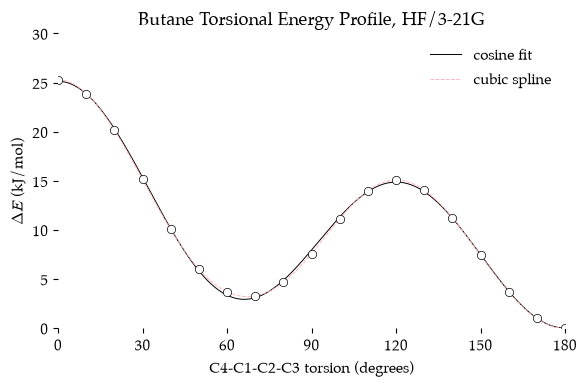

eclipsed maximum: 120.1 degrees, 14.87 kJ/mol
gauche minimum:   66.1 degrees, 2.93 kJ/mol


In [60]:
y_cos = cosine_series(x_fit, *params)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(x_fit, y_cos, color="black", linewidth=0.7, zorder=1, label="cosine fit")
ax.plot(x_fit, y_fit, color="#FFB3BA", linewidth=0.7, linestyle="--", zorder=1, label="cubic spline")
ax.plot(butane["Torsion"], butane["DeltaE"], linestyle="none", marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.set_xlabel("C4-C1-C2-C3 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butane Torsional Energy Profile, HF/3-21G")
ax.set_xlim(0, 180)
ax.set_ylim(0, 30)
ax.set_xticks(np.arange(0, 181, 30))
ax.legend()
plt.show()

region = (x_fit > 90) & (x_fit < 150)
i_max = np.argmax(y_cos[region])
print(f"eclipsed maximum: {x_fit[region][i_max]:.1f} degrees, {y_cos[region][i_max]:.2f} kJ/mol")

region = (x_fit > 30) & (x_fit < 90)
i_min = np.argmin(y_cos[region])
print(f"gauche minimum:   {x_fit[region][i_min]:.1f} degrees, {y_cos[region][i_min]:.2f} kJ/mol")

| Line | Notes |
| :---- | :---- |
| `cosine_series(x_fit, *params)` | The fitted curve at every 0.1&deg;, using the same angles as the spline. |
| `linestyle="--"` | The spline from the previous section, drawn as a pale **dashed** line for comparison. |

By eye, the two curves are almost **identical**. Look closely, though, and the cosine fit misses some points by a few tenths of a *kJ/mol*. Four cosines cannot quite capture every detail of the profile. The cosine fit puts the *eclipsed* maximum at 120.1&deg; (14.87 *kJ/mol*) and the *gauche* minimum at 66.1&deg; (2.93 *kJ/mol*), slightly lower and shallower than the spline and the real *gauche* optimization (67.20&deg;, 3.21 *kJ/mol*).

So which is better? The spline is better at **reproducing** the data, because it is forced through every point. The cosine fit is better at **understanding** the data. It is a smooth, periodic function that is correct for the whole 360&deg; turn, and its parameters tell us *why* the curve has the shape it has: an ethane-like threefold barrier plus a methyl&ndash;methyl bump. This is exactly the form that **force fields** used in molecular mechanics use to describe torsions.

```{tip}
Add more terms, $a_4 \cos 4\phi$, $a_5 \cos 5\phi$ and $a_6 \cos 6\phi$, to `cosine_series()` and fit again. With seven parameters, the RMS residual falls to 0.04 *kJ/mol* and the *gauche* minimum moves to 67.0&deg; (3.15 *kJ/mol*). But the new parameters are small and have no simple chemical meaning. When do more parameters stop being science and become connect-the-dots again?
```

## Comparing Levels of Theory

In the previous section we also ran the scan at the HF/6-311++G(d,p) level. Let us process that data the **same** way, fit a cosine series to **both** profiles and put them on one plot. The fitted parameters give us a way to compare the two levels of theory term by term. Since we will do the same thing twice, we will write a small function.

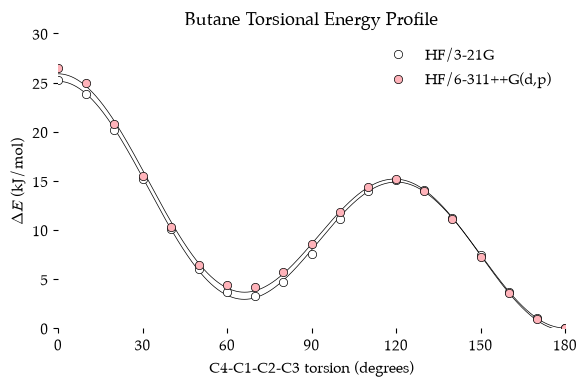

,Torsion,HF/3-21G,"HF/6-311++G(d,p)"
0,0,25.26,26.51
1,10,23.88,24.93
2,20,20.16,20.82
3,30,15.13,15.50
4,40,10.04,10.32
5,50,5.99,6.39
6,60,3.69,4.35
7,70,3.28,4.23
8,80,4.67,5.76
9,90,7.59,8.53


,Level,a0,a1,a2,a3,RMS residual,gauche angle,gauche dE,eclipsed angle,eclipsed dE
0,HF/3-21G,10.26,4.53,2.31,8.03,0.17,66.1,2.93,120.1,14.87
1,"HF/6-311++G(d,p)",10.70,5.01,2.13,8.05,0.30,66.2,3.65,119.4,15.18


In [61]:
def relative_energies(df):
    df = df.dropna(subset=["Energy"])
    df = df[["Torsion", "Energy", "Steps"]].copy()
    df["DeltaE"] = (df["Energy"] - df["Energy"].min()) * hartree_conversion
    return df

butane_6311 = relative_energies(load_scan("butane_scan_HF6311ppGdp.json"))

fits = []

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
for data, label, color in [(butane, "HF/3-21G", "white"),
                           (butane_6311, "HF/6-311++G(d,p)", "#FFB3BA")]:
    params, covariance = curve_fit(cosine_series, data["Torsion"], data["DeltaE"])
    y_cos = cosine_series(x_fit, *params)
    residuals = data["DeltaE"] - cosine_series(data["Torsion"], *params)

    gauche = (x_fit > 30) & (x_fit < 90)
    eclipsed = (x_fit > 90) & (x_fit < 150)
    fits.append({"Level": label,
                 "a0": params[0], "a1": params[1], "a2": params[2], "a3": params[3],
                 "RMS residual": np.sqrt(np.mean(residuals**2)),
                 "gauche angle": x_fit[gauche][np.argmin(y_cos[gauche])],
                 "gauche dE": np.min(y_cos[gauche]),
                 "eclipsed angle": x_fit[eclipsed][np.argmax(y_cos[eclipsed])],
                 "eclipsed dE": np.max(y_cos[eclipsed])})

    ax.plot(x_fit, y_cos, color="black", linewidth=0.5, zorder=1)
    ax.plot(data["Torsion"], data["DeltaE"], linestyle="none", marker="o", label=label,
            markerfacecolor=color, markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.set_xlabel("C4-C1-C2-C3 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butane Torsional Energy Profile")
ax.set_xlim(0, 180)
ax.set_ylim(0, 30)
ax.set_xticks(np.arange(0, 181, 30))
ax.legend()
plt.show()

comparison = pd.DataFrame({"Torsion": butane["Torsion"],
                           "HF/3-21G": butane["DeltaE"],
                           "HF/6-311++G(d,p)": butane_6311["DeltaE"]})
display(comparison.round(2))

pd.DataFrame(fits).round(2)

| Line | Notes |
| :---- | :---- |
| `def relative_energies(df):` | The cleaning and processing steps from above, wrapped in a **function**. `.copy()` makes a new dataframe so that *pandas* does not worry that we are changing the original. |
| `fits = []` | An empty list to collect the fitted **parameters** for each level of theory. |
| `for data, label, color in [...]` | Fits the cosine series and draws the curve and the points for **each** level of theory: open circles for HF/3-21G and pastel pink for HF/6-311++G(d,p). |
| `curve_fit(cosine_series, ...)` | The same fit as in the previous section, using our `cosine_series()` function. |
| `gauche`, `eclipsed` | The two **regions** in which we look for the minimum and the maximum of the fitted curve. |
| `fits.append({...})` | Stores the four parameters, the RMS residual and the positions and energies of the *gauche* minimum and *eclipsed* maximum. |
| `label=label`, `ax.legend()` | Labels each set of points and draws a **legend**. |
| `display(...)` | Shows a table in the middle of a cell. Only the **last** line of a cell is displayed automatically. |

You can see that they are very similar. The larger basis set raises the *syn* barrier a little (26.51 vs 25.26 *kJ/mol*), leaves the *eclipsed* barrier almost unchanged (15.19 vs 15.07 *kJ/mol*) and raises the *gauche* valley by about 1 *kJ/mol* (4.23 vs 3.28 *kJ/mol* at 70&deg;), closer to the literature value of 3.8 *kJ/mol*. In the *GAMESS* book, the larger basis set moved the *gauche* minimum from 67&deg; to 65&deg; and left the **energy profile** very similar. When using 1st and 2nd row elements with no charges or strained bonds, the 3-21G basis set gives good results.

The cosine fits tell us **where** the difference comes from. The **threefold** term is the same at both levels ($a_3$ = 8.03 and 8.05 *kJ/mol*). The ethane-like barrier does not care about the basis set. The **onefold** term, the methyl groups bumping into each other, is larger with the bigger basis set ($a_1$ = 4.53 vs 5.01 *kJ/mol*). That pushes the *gauche* valley up (2.93 vs 3.65 *kJ/mol* from the fits) while leaving its position almost unchanged (66.1&deg; vs 66.2&deg;). The *eclipsed* maximum stays close to 120&deg; at both levels (120.1&deg; and 119.4&deg;). Four cosines still describe the HF/6-311++G(d,p) profile well, although the RMS residual (0.30 *kJ/mol*) is a little larger than for HF/3-21G (0.17 *kJ/mol*).

## Saving the Data

We have imported, cleaned and processed the data. Maybe we should save our work so we can use this data set directly and easily next time. The dataframe object contains methods to do this. We will use the `pandas.DataFrame.to_csv()` method ([documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html)) to save the dataframe object as a csv text file, which any spreadsheet program can open.

In [62]:
comparison.to_csv("butane_profile.csv", index=False)

| Line | Notes |
| :---- | :---- |
| `index=False` | Do not write the row numbers (0, 1, 2&hellip;) into the file. |

The butane energy profile data is now saved in a file named `butane_profile.csv`, with one row for each torsion angle and one column for each level of theory.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Data Workflow" notebook of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **a fifth** of the text is **my own work**, carried over word for word or lightly edited, including the descriptions of importing, cleaning, processing, plotting and saving the data and the cubic spline. The **rest of the page** was written by an **LLM system** at my request. I asked it to read the JSON files written by the *Psi4* workflow instead of the *GAMESS* log file extracts, to find the maximum and minimum from the spline, to add a section fitting a cosine series to the profile, and to compare the two levels of theory using those fits. The *Python* code, the line-by-line explanations of it, the discussion of the cosine series and the commentary on the results were written by the LLM. The numbers quoted in the text come from my own calculations.
```